# 01 · Audit & Pembersihan Data
**Kasus 08 – Prediksi Keterlambatan Paket (hub Bandung).**
Brief menyatakan data *"belum diperiksa oleh siapa pun"*, jadi langkah pertama adalah audit sistematis. Prinsipnya: **setiap aturan cleaning harus punya bukti** di notebook ini, lalu dipindahkan ke `src/features.py:clean()` agar sama persis di training dan di aplikasi.

Ringkasan temuan (dibuktikan di bawah):
| # | Masalah | Keputusan |
|---|---|---|
| 1 | 500 baris duplikat persis | hapus **sebelum** split |
| 2 | `layanan` 7 varian, `kota_tujuan` 28 varian | normalisasi dengan mapping |
| 3 | `berat_kg` campur kg & gram (+ nilai −1) | >50 → bagi 1000; ≤0 → NaN |
| 4 | `jarak_km` (813) & `cuaca` (406) kosong | imputasi (statistik dari train saja) |
| 5 | `volume_hub_hari` berekor panjang | **bukan error**: hari puncak nyata → pertahankan |

In [1]:
import sys; sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.features import clean, GRAM_THRESHOLD
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
raw = pd.read_csv('../data/raw.csv')
print(raw.shape); raw.head()

(40500, 13)


,id_resi,tanggal_pickup,jam_pickup,kota_tujuan,jarak_km,jumlah_transit,layanan,janji_hari,berat_kg,metode_bayar,cuaca_saat_pickup,volume_hub_hari,terlambat
0,BDG69958899,2025-01-01,14,Tasikmalaya,109.0,2,HEMAT,4,5.93,COD,berawan,4990,0
1,BDG98718051,2025-01-01,15,Surabaya,678.0,2,HEMAT,5,0.78,non_COD,berawan,4769,0
2,BDG40074637,2025-01-01,14,Bekasi,128.0,1,REG,2,2.57,COD,cerah,4286,0
3,BDG00168612,2025-01-01,14,Pontianak,885.0,3,REG,3,1.12,COD,cerah,4856,1
4,BDG72495951,2025-01-01,12,Denpasar,1057.0,3,EXPRESS,3,1.68,non_COD,berawan,5467,0


## 1. Struktur, missing value, duplikat
Alasan: duplikat yang jatuh ke train *dan* test membuat skor evaluasi terlalu optimis (model "menghafal" baris yang sama), sehingga harus dibuang sebelum split.

In [2]:
print(raw.dtypes.to_string()); print()
print('Missing per kolom:'); print(raw.isna().sum()[lambda s: s > 0])
print('\nid_resi duplikat :', raw.id_resi.duplicated().sum())
print('baris duplikat penuh:', raw.duplicated().sum())
print('id duplikat tapi baris beda:', (raw.id_resi.duplicated() & ~raw.duplicated()).sum())

id_resi                  str
tanggal_pickup           str
jam_pickup             int64
kota_tujuan              str
jarak_km             float64
jumlah_transit         int64
layanan                  str
janji_hari             int64
berat_kg             float64
metode_bayar             str
cuaca_saat_pickup        str
volume_hub_hari        int64
terlambat              int64

Missing per kolom:
jarak_km             813
cuaca_saat_pickup    406
dtype: int64

id_resi duplikat : 500
baris duplikat penuh: 500
id duplikat tapi baris beda: 0


→ Semua duplikat `id_resi` adalah **duplikat baris penuh** (termasuk target), jadi aman dibuang. Rentang tanggal juga perlu dicek.

In [3]:
t = pd.to_datetime(raw.tanggal_pickup, errors='coerce'); print('tanggal gagal parse:', t.isna().sum(), '|', t.min().date(), '→', t.max().date())
print('jam_pickup:', raw.jam_pickup.min(), '-', raw.jam_pickup.max(), '| terlambat unik:', sorted(raw.terlambat.unique()))

tanggal gagal parse: 0 | 2025-01-01 → 2026-06-30
jam_pickup: 7 - 22 | terlambat unik: [np.int64(0), np.int64(1)]


## 2. Kategori kotor: `layanan` dan `kota_tujuan`
Model akan menganggap `EXP` dan `EXPRESS` sebagai dua kategori berbeda → sinyal terpecah dan kategori kecil menjadi noise. Kita petakan varian ke bentuk kanonik.

In [4]:
print(raw.layanan.value_counts().to_string()); print(); print('kota unik mentah:', raw.kota_tujuan.nunique())
print(sorted(raw.kota_tujuan.unique()))

layanan
REG        23704
HEMAT       8001
EXPRESS     7983
Express      213
hemat        213
EXP          212
reg          174

kota unik mentah: 28
['Bali', 'Balikpapan', 'Bekasi', 'Bogor', 'Cirebon', 'DI Yogyakarta', 'DKI Jakarta', 'Denpasar', 'Jakarta', 'Jkt', 'Jogja', 'Kota Bekasi', 'MEDAN', 'Makassar', 'Malang', 'Medan', 'Palembang', 'Pontianak', 'Sby', 'Semarang', 'Surabaya', 'Tasikmalaya', 'Yogya', 'Yogyakarta', 'bekasi', 'denpasar', 'jakarta', 'surabaya']


In [5]:
d = clean(raw)
print('Setelah normalisasi → layanan:', sorted(d.layanan.unique()), '| kota:', d.kota_tujuan.nunique())
assert d.layanan.notna().all() and d.kota_tujuan.nunique() == 15

Setelah normalisasi → layanan: ['EXPRESS', 'HEMAT', 'REG'] | kota: 15


**Validasi mapping lewat `jarak_km`:** jarak seharusnya konsisten per kota. Jika mapping benar, rentang jarak tiap kota sempit (± puluhan km) dan tidak ada kota yang rentangnya campur aduk.

In [6]:
print(d.groupby('kota_tujuan').jarak_km.agg(['min','median','max','count']).round(0).sort_values('median'))

                min  median     max  count
kota_tujuan                               
Tasikmalaya    90.0   110.0   128.0   2029
Bogor         104.0   125.0   146.0   3140
Cirebon       102.0   130.0   152.0   1966
Bekasi        110.0   130.0   151.0   3944
Jakarta       121.0   150.0   179.0   7831
Semarang      287.0   370.0   436.0   2695
Yogyakarta    328.0   390.0   454.0   2736
Surabaya      564.0   691.0   811.0   3428
Malang        609.0   720.0   851.0   1657
Palembang     717.0   860.0   997.0   1552
Pontianak     764.0   900.0  1043.0   1219
Denpasar      879.0  1080.0  1248.0   1942
Balikpapan   1176.0  1400.0  1678.0   1557
Makassar     1221.0  1498.0  1769.0   1578
Medan        1600.0  1899.0  2194.0   1926


→ Rentang per kota sempit dan tidak tumpang tindih antar-kota → mapping valid. Karena jarak ≈ fungsi kota, **jarak yang hilang diimputasi dengan median kota** (bukan median global).

### Konsistensi `layanan` × `janji_hari`
SLA seharusnya mengikuti layanan (EXPRESS 1–3, REG 2–4, HEMAT 4–6 hari).

In [7]:
print(pd.crosstab(raw.layanan, raw.janji_hari))

janji_hari     1      2     3     4     5     6
layanan                                        
EXP           24     69    61    38    12     8
EXPRESS     3829   2740  1414     0     0     0
Express       23     80    51    41    11     7
HEMAT          0      0     0  3869  2767  1365
REG            0  11440  8069  4195     0     0
hemat         16     70    52    48    19     8
reg           18     66    44    34    10     2


**Temuan:** pada label bersih (EXPRESS/REG/HEMAT) pola SLA rapi, sedangkan ±800 baris (±2%) berlabel varian (`EXP`, `Express`, `hemat`, `reg`) punya `janji_hari` yang tersebar 1–6, jadi tidak cocok dengan layanan hasil normalisasi. Penyebabnya tidak bisa dipastikan dari data (label atau SLA yang rusak). Keputusan: pakai `janji_hari` apa adanya (itu janji yang diberikan ke pelanggan) dan catat sebagai **pertanyaan untuk klien**. Dampaknya kecil (±2% baris, tingkat terlambat varian 17,5% vs 17,8% bersih).

## 3. `berat_kg`: satuan campur
Median berat ±1,4 kg, tetapi maksimum 28.310. Hipotesis: sebagian baris tercatat dalam **gram**.

count    40500.00
mean        61.99
std        530.14
min         -1.00
25%          0.74
50%          1.38
75%          2.64
max      28310.00
≤0: 81 | >50: 1208


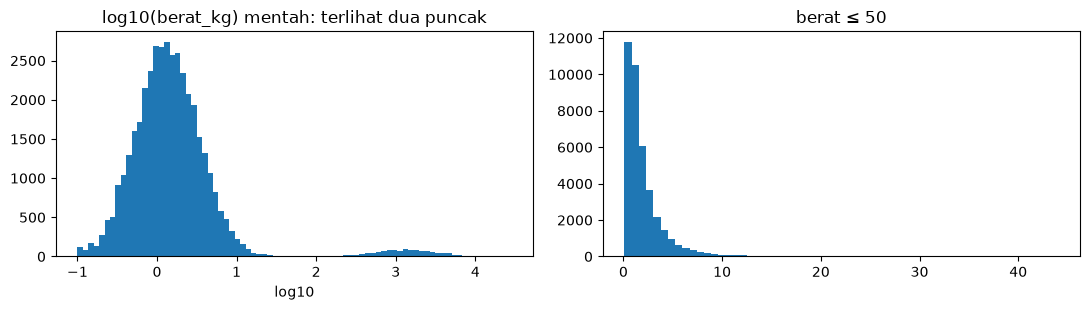

In [8]:
b = raw.berat_kg
print(b.describe().round(2).to_string()); print('≤0:', (b <= 0).sum(), '| >50:', (b > 50).sum())
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].hist(np.log10(b[b > 0]), bins=80); ax[0].set_title('log10(berat_kg) mentah: terlihat dua puncak'); ax[0].set_xlabel('log10')
ax[1].hist(b[(b > 0) & (b <= 50)], bins=60); ax[1].set_title('berat ≤ 50'); plt.tight_layout()

In [9]:
normal, besar = b[(b > 0) & (b <= GRAM_THRESHOLD)], b[b > GRAM_THRESHOLD]
print(f'median normal = {normal.median():.2f} kg | median "besar" / 1000 = {besar.median()/1000:.2f} kg')
print(f'rentang normal  : {normal.min():.2f} .. {normal.max():.2f}   |  rentang besar: {besar.min():.0f} .. {besar.max():.0f}')
print('kuantil normal :', normal.quantile([.1,.5,.9]).round(2).to_dict())
print('kuantil besar/1000:', (besar/1000).quantile([.1,.5,.9]).round(2).to_dict())

median normal = 1.34 kg | median "besar" / 1000 = 1.33 kg
rentang normal  : 0.10 .. 44.06   |  rentang besar: 100 .. 28310
kuantil normal : {0.1: 0.43, 0.5: 1.34, 0.9: 4.31}
kuantil besar/1000: {0.1: 0.42, 0.5: 1.33, 0.9: 4.19}


→ Distribusi `besar/1000` hampir identik dengan distribusi normal (median ≈1,33 vs 1,34 kg) dan tidak ada nilai di celah 44–100 → **bukti kuat satuan gram**. Aturan: `>50 → /1000`; `≤0 → NaN` (berat nol/negatif mustahil). Catatan jujur: di notebook 02 terbukti perbaikan ini **tidak mengubah skor** (berat nyaris tanpa sinyal). Tetap dilakukan demi integritas data dan agar aplikasi tidak menerima nilai absurd atau menyalahartikan satuan.

## 4. `volume_hub_hari`: outlier atau sinyal?
Ekor panjang (maks 17.979) bisa jadi error input *atau* hari puncak sungguhan. Uji: apakah nilai tinggi **mengelompok pada tanggal tertentu** dan **berhubungan dengan target**?

In [10]:
d['bulan'] = d.tanggal_pickup.dt.to_period('M'); d['tgl'] = d.tanggal_pickup.dt.date
harian = d.groupby('tgl').agg(vol=('volume_hub_hari','median'), terlambat=('terlambat','mean'), n=('terlambat','size'))
hari_puncak = harian[harian.vol > 8000]
print('hari dengan volume median > 8000:', len(hari_puncak), 'dari', len(harian), 'hari')
print(hari_puncak.index.map(lambda x: str(x)[:7]).value_counts().sort_index().to_dict())
print('tingkat terlambat hari puncak vs biasa:', hari_puncak.terlambat.mean().round(3), harian[harian.vol <= 8000].terlambat.mean().round(3))

hari dengan volume median > 8000: 36 dari 546 hari
{'2025-03': 13, '2025-11': 5, '2025-12': 5, '2026-03': 13}
tingkat terlambat hari puncak vs biasa: 0.662 0.143


→ Volume tinggi **mengelompok di Maret (2025 & 2026) dan Nov–Des** (musim Lebaran/Harbolnas) dan di hari itu ±75% paket terlambat. Ini **sinyal operasional nyata**, bukan outlier error → **dipertahankan** (tidak di-clip atau dibuang). Catatan: nilai ini berbeda antar-baris pada hari yang sama (±600 std), jadi diperlakukan sebagai ukuran beban hub saat pickup.

## 5. Pola waktu (bekal EDA & desain split)

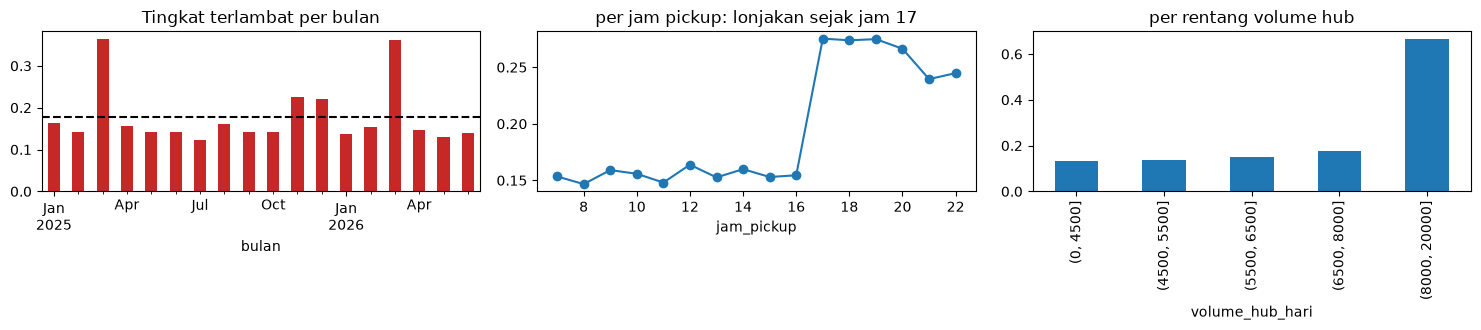

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
d.groupby('bulan').terlambat.mean().plot(kind='bar', ax=ax[0], color='#c62828'); ax[0].set_title('Tingkat terlambat per bulan'); ax[0].axhline(d.terlambat.mean(), ls='--', c='k')
d.groupby('jam_pickup').terlambat.mean().plot(ax=ax[1], marker='o'); ax[1].set_title('per jam pickup: lonjakan sejak jam 17')
d.groupby(pd.cut(d.volume_hub_hari, [0,4500,5500,6500,8000,20000])).terlambat.mean().plot(kind='bar', ax=ax[2]); ax[2].set_title('per rentang volume hub')
plt.tight_layout()

**Implikasi desain:** (a) ada musim puncak: split waktu harus disadari komposisinya; (b) jam ≥17 ibarat *cut-off* sortir; (c) volume berpola ambang bukan garis lurus; fitur turunan di notebook 02.

## 6. Terapkan `clean()` dan verifikasi

In [12]:
dc = clean(raw)
assert len(dc) == raw.drop_duplicates().shape[0] == 40000 and dc.id_resi.is_unique
assert set(dc.layanan) == {'EXPRESS','REG','HEMAT'} and dc.kota_tujuan.nunique() == 15
assert dc.berat_kg.max() < 50 and dc.berat_kg.min() > 0
print(dc.berat_kg.describe().round(2).to_string()); print('\nmissing tersisa:'); print(dc.isna().sum()[lambda s: s > 0])
print(f'\ntingkat terlambat: {dc.terlambat.mean():.3f}')

count    39920.00
mean         2.03
std          2.29
min          0.10
25%          0.73
50%          1.34
75%          2.46
max         44.06

missing tersisa:
jarak_km             800
berat_kg              80
cuaca_saat_pickup    400
dtype: int64

tingkat terlambat: 0.178


Missing `jarak_km` (±2%) dan `cuaca` (±1%) **sengaja tidak diisi di sini**: imputasi memakai statistik (median) yang harus dihitung **dari data train saja**, sehingga dilakukan di dalam `FeatureBuilder.fit()` pada notebook 02. Missing `cuaca` tidak acak: dijadikan kategori `tidak_diketahui`, sehingga model bebas menilai maknanya.

**Lanjut ke `02_modeling.ipynb`.**